# 10. Evaluación de los modelos de regresión

Objetivo: `log(1 + días de ausencia)` en los casos que terminaron en días de ausencia (capítulo 4).
7 modelos × 4 optimizadores = 28 combinaciones, sin balanceo (no aplica en regresión). Igual que en
clasificación, la mejor combinación de cada modelo se elige por el RMSE externo de la validación
anidada y luego se evalúa una vez en la prueba (45.861 casos de octubre a diciembre).

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import het_white, acorr_ljungbox
from statsmodels.tsa.stattools import bds, acf
from statsmodels.graphics.tsaplots import plot_acf
from osha_e3 import config as C, data as D, models as M, nested as N, final as F, evaluation as E, plots as P, search as S, cache
P.setup()
mr = N.master_table('reg'); tr_ = F.test_table('reg').set_index('combo')
test, yt = F.test_data('reg')
MODELS, OPTS = P.MODEL_ORDER_REG, M.OPTIMIZERS
fmt = lambda m, s: f'{m:.3f} ± {s:.3f}'

## 10.1 Las 28 combinaciones en la validación anidada

In [2]:
mr['Combinación'] = mr.model.map(M.PRETTY) + ' · ' + mr.optimizer.map(M.PRETTY)
t = mr.sort_values('outer_rmse_mean')
pd.DataFrame({'RMSE externo': [fmt(a, b) for a, b in zip(t.outer_rmse_mean, t.outer_rmse_std)],
              'MAE externo': [fmt(a, b) for a, b in zip(t.outer_mae_mean, t.outer_mae_std)],
              'R² externo': [fmt(a, b) for a, b in zip(t.outer_r2_mean, t.outer_r2_std)],
              'Búsqueda (min·núcleo)': (t.search_seconds_total / 60).round(1).to_numpy()},
             index=t['Combinación'])

,RMSE externo,MAE externo,R² externo,Búsqueda (min·núcleo)
Combinación,,,,
Random Forest · Random,1.364 ± 0.008,1.143 ± 0.008,0.066 ± 0.006,19.3
Random Forest · Genética,1.365 ± 0.010,1.143 ± 0.009,0.065 ± 0.008,18.7
Random Forest · Bayesiana (TPE),1.365 ± 0.009,1.143 ± 0.009,0.064 ± 0.006,22.1
XGBoost · Bayesiana (TPE),1.365 ± 0.011,1.143 ± 0.011,0.064 ± 0.009,2.6
Random Forest · Grid,1.365 ± 0.010,1.144 ± 0.011,0.064 ± 0.007,22.1
XGBoost · Grid,1.365 ± 0.011,1.144 ± 0.011,0.064 ± 0.010,3.1
XGBoost · Genética,1.366 ± 0.010,1.145 ± 0.010,0.063 ± 0.007,2.5
XGBoost · Random,1.366 ± 0.011,1.145 ± 0.013,0.063 ± 0.007,2.6
Lasso · Random,1.367 ± 0.012,1.147 ± 0.010,0.061 ± 0.011,3.2


**Interpretación.** Las 28 combinaciones quedan en un rango estrecho: RMSE externo entre 1,364 y 1,381 y R² entre 0,04 y
0,07. Los modelos de árboles en ensamble (Random Forest y XGBoost) encabezan la tabla, seguidos de cerca
por Lasso y Ridge; SVR, el árbol simple y KNN quedan al final. Las diferencias entre optimizadores dentro de
un mismo modelo (≤ 0,004 de RMSE) son menores que la desviación entre pliegues (≈ 0,01): con este
presupuesto, el método de búsqueda importa poco en regresión (capítulo 7). El costo sí cambia mucho:
Random Forest gastó unos 20 minutos·núcleo de búsqueda por combinación y XGBoost unos 3 para el mismo
RMSE. Con estas variables se explica solo alrededor del 6 % de la varianza de log(1 + días): la duración
de una ausencia depende sobre todo de la lesión concreta, que el modelo no ve.

## 10.2 Mejor combinación de cada modelo: métricas y supuestos en la prueba

- **Test de White** (homocedasticidad): regresión auxiliar de los residuos al cuadrado sobre las
  predicciones y su cuadrado (la forma «especial» del test de White, que evita los miles de
  productos cruzados de 210 columnas binarias). H0: varianza constante.
- **Test BDS** (independencia, Brock-Dechert-Scheinkman): sobre los residuos ordenados por fecha.
  El estadístico es O(n²) en memoria, así que se aplica a 3.000 residuos equiespaciados en el
  tiempo, dimensión de inmersión 2. H0: residuos i.i.d.

Con 45.861 casos cualquier desviación pequeña sale significativa; por eso los p-valores se leen
junto con las gráficas de 12.4.

In [3]:
best = mr.loc[mr.groupby('model').outer_rmse_mean.idxmin()].set_index('model').reindex(MODELS)
best_combo = best.combo.to_dict()
preds = {m: F.load('reg', best_combo[m])[0].astype(float) for m in MODELS}
order = np.argsort(test.date.to_numpy(), kind='stable')
idx_bds = order[np.linspace(0, len(order) - 1, 3000).astype(int)]
def white_p(res, fit):
    exog = np.column_stack([np.ones_like(fit), fit])
    return het_white(res, exog)[1]
rows = []
for m in MODELS:
    p = preds[m]; res = yt - p
    rows.append({'Modelo': M.PRETTY[m], 'Optimizador': M.PRETTY[best.loc[m, 'optimizer']],
                 'RMSE anidado': fmt(best.loc[m, 'outer_rmse_mean'], best.loc[m, 'outer_rmse_std']),
                 'RMSE prueba': tr_.loc[best_combo[m], 'test_rmse'], 'MAE prueba': tr_.loc[best_combo[m], 'test_mae'],
                 'R² prueba': tr_.loc[best_combo[m], 'test_r2'],
                 'p-valor (White)': white_p(res, p), 'p-valor (BDS, m=2)': float(bds(res[idx_bds], max_dim=2)[1])})
base = np.full_like(yt, N.task_data('reg')[1].mean())
rows.append({'Modelo': 'Referencia: media del entrenamiento', 'Optimizador': '—', 'RMSE anidado': '—',
             'RMSE prueba': E.regression_metrics(yt, base)['rmse'], 'MAE prueba': E.regression_metrics(yt, base)['mae'],
             'R² prueba': E.regression_metrics(yt, base)['r2'], 'p-valor (White)': np.nan, 'p-valor (BDS, m=2)': np.nan})
reg_table = pd.DataFrame(rows).set_index('Modelo')
reg_table.round(4)

,Optimizador,RMSE anidado,RMSE prueba,MAE prueba,R² prueba,p-valor (White),"p-valor (BDS, m=2)"
Modelo,,,,,,,
KNN,Grid,1.380 ± 0.012,1.1659,0.9571,-0.0235,0.0,0.8976
Ridge,Genética,1.367 ± 0.011,1.1511,0.9432,0.0023,0.0,0.8668
Lasso,Random,1.367 ± 0.012,1.1494,0.9422,0.0052,0.0,0.8740
Árbol,Grid,1.378 ± 0.012,1.1534,0.9418,-0.0016,0.0,0.8783
Random Forest,Random,1.364 ± 0.008,1.1431,0.9310,0.0162,0.0,0.8529
XGBoost,Bayesiana (TPE),1.365 ± 0.011,1.1437,0.9345,0.0152,0.0,0.8703
SVR,Grid,1.370 ± 0.014,1.1512,0.9451,0.0023,0.0,0.8763
Referencia: media del entrenamiento,—,—,1.1885,1.0272,-0.0636,NaN,NaN


**Interpretación.** En la prueba el orden se mantiene (Random Forest y XGBoost primero, KNN último), pero aparecen dos cosas
que la validación no mostraba:

1. **El RMSE baja** (1,14 frente a 1,36) **y el R² se hunde** (0,016 en el mejor modelo, negativo en KNN y
   el árbol). No es que el modelo mejore: la prueba tiene menos dispersión (desviación de 1,15 frente a 1,41
   en el entrenamiento) y un nivel más bajo (media 2,44 frente a 2,73). Hasta la referencia que predice la
   media del entrenamiento obtiene R² = −0,064.
2. **Sesgo sistemático:** el 58 % de los residuos son negativos y el residuo medio es −0,22 (el modelo
   sobrestima). El sesgo crece mes a mes: −0,12 en octubre, −0,21 en noviembre y −0,34 en diciembre.

La causa más probable es **censura a la derecha** de la etiqueta. El archivo se cierra con el reporte
anual: un caso de diciembre no puede acumular 180 días de ausencia antes de esa fecha. En los datos, los
casos con 180 días o más pasan de cerca del 8 % (enero a junio) al 0,5 % (diciembre). Es la «maduración de la
etiqueta» que el entregable 2 dejó anotada como posible y que aquí se confirma. Si se quita el sesgo medio,
el R² del mejor modelo en la prueba sube de 0,016 a 0,053, cerca del 0,066 de la validación anidada.

**Supuestos.** El test de White rechaza la homocedasticidad en todos los modelos (p ≈ 0): la varianza del
residuo cambia con la predicción, en parte por la forma acotada del objetivo y por la censura. BDS no
rechaza la independencia (p entre 0,85 y 0,90), pero los 3.000 residuos usados están muy separados en el
tiempo; Ljung-Box (sección 10.4) sí detecta dependencia entre residuos cercanos.

## 10.3 Entrenamiento, validación y prueba con sus predicciones

Para el mejor modelo se reajusta con 4 de los 5 pliegues externos (entrenamiento), se predice el
pliegue restante (validación) y la prueba. La gráfica muestra, por semana, el promedio real y
el predicho de `log(1 + días)` en cada conjunto; abajo, predicho frente a real caso a caso.

Mejor modelo de regresión: Random Forest · Random {"n_estimators": 183, "max_depth": 24, "min_samples_leaf": 3, "max_features": 0.078924016621189}


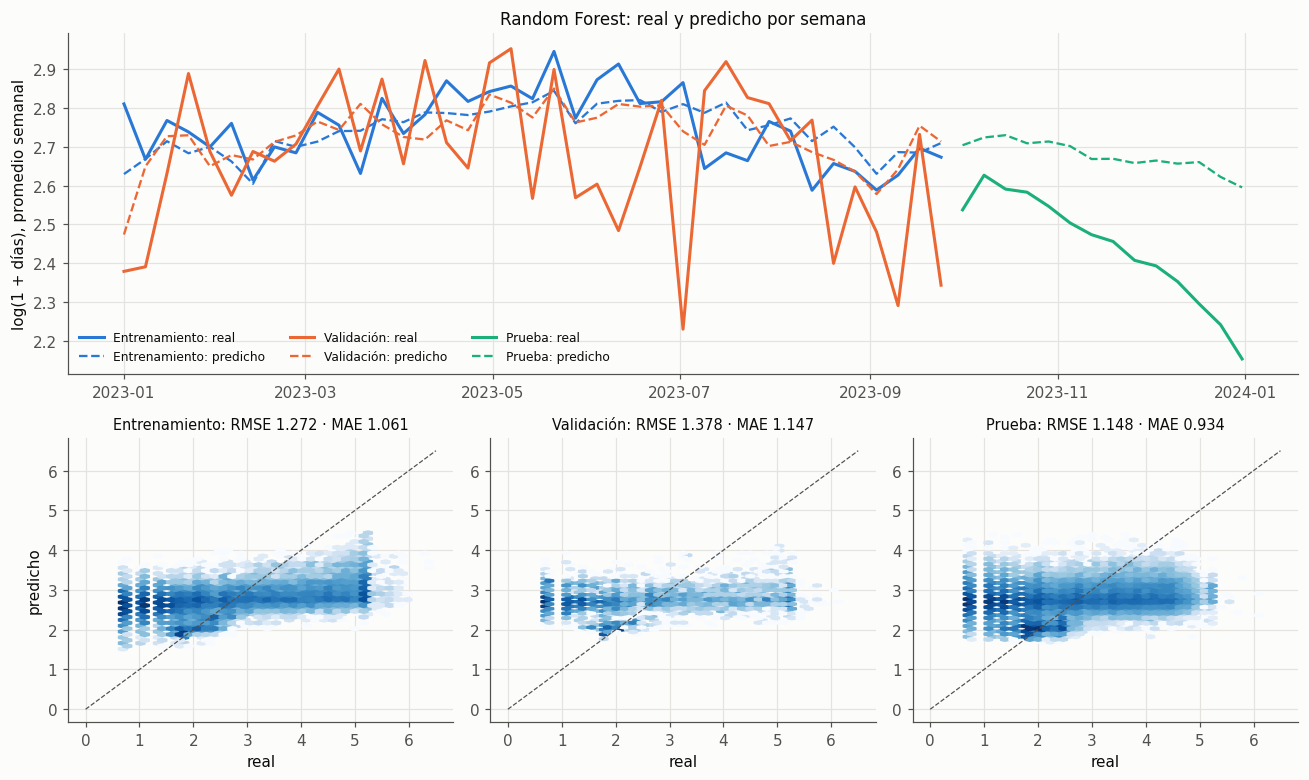

In [4]:
bm = min(MODELS, key=lambda m: best.loc[m, 'outer_rmse_mean'])
print('Mejor modelo de regresión:', M.PRETTY[bm], '·', M.PRETTY[best.loc[bm, 'optimizer']], best.loc[bm, 'final_params'])
sub_r, dev_r, _ = D.regression_sets()
X, y, g, s = N.task_data('reg')
tr_i, va_i = N.outer_folds('reg')[0]
def run_tvt():
    pipe = S.refit('reg', bm, json.loads(best.loc[bm, 'final_params']), 'none', X.iloc[tr_i], y[tr_i], C.SEED)
    return {'train': pipe.predict(X.iloc[tr_i]), 'valid': pipe.predict(X.iloc[va_i]), 'test': pipe.predict(test[D.FEATURES])}
tvt = cache.cached('reg_train_valid_test', run_tvt)
parts = [('Entrenamiento', sub_r.iloc[tr_i].date, y[tr_i], tvt['train'], P.SERIES[0]),
         ('Validación', sub_r.iloc[va_i].date, y[va_i], tvt['valid'], P.SERIES[1]),
         ('Prueba', test.date, yt, tvt['test'], P.SERIES[2])]
fig = plt.figure(figsize=(12, 7.2)); gs = fig.add_gridspec(2, 3, height_ratios=[1.2, 1])
ax = fig.add_subplot(gs[0, :])
for name, d, yy, pp, col in parts:
    w = pd.DataFrame({'d': pd.to_datetime(d).to_numpy(), 'y': yy, 'p': pp}).set_index('d').resample('W').mean()
    ax.plot(w.index, w.y, color=col, lw=2, label=f'{name}: real')
    ax.plot(w.index, w.p, color=col, lw=1.5, ls='--', label=f'{name}: predicho')
ax.set_ylabel('log(1 + días), promedio semanal'); ax.set_title(f'{M.PRETTY[bm]}: real y predicho por semana')
ax.legend(ncol=3, fontsize=8, loc='lower left')
for i, (name, d, yy, pp, col) in enumerate(parts):
    a = fig.add_subplot(gs[1, i])
    a.hexbin(yy, pp, gridsize=35, cmap='Blues', mincnt=1, bins='log')
    a.plot([0, 6.5], [0, 6.5], color=P.INK2, ls='--', lw=0.8)
    met = E.regression_metrics(yy, pp)
    a.set_title(f'{name}: RMSE {met["rmse"]:.3f} · MAE {met["mae"]:.3f}', fontsize=9.5)
    a.set_xlabel('real'); a.set_ylabel('predicho' if i == 0 else '')
fig.tight_layout(); P.save(fig, 'e3_reg_train_valid_test'); plt.show()

**Interpretación.** El modelo sigue bien el nivel medio del entrenamiento (RMSE 1,27) y de la validación (1,38). La serie de
validación es más irregular porque cada semana tiene pocos establecimientos de un solo pliegue. En la
prueba la diferencia es visible: el promedio real cae de forma sostenida de unos 2,6 a 2,15 entre octubre y
fin de año, mientras la predicción queda casi plana en torno a 2,6–2,7. Es la huella de la censura descrita
arriba. Caso a caso (abajo), las predicciones se concentran entre 2 y 3,5 sea cual sea el valor real: el
modelo apenas separa ausencias cortas de largas, consistente con un R² de 0,05 a 0,07.

## 10.4 Análisis de residuos del mejor modelo

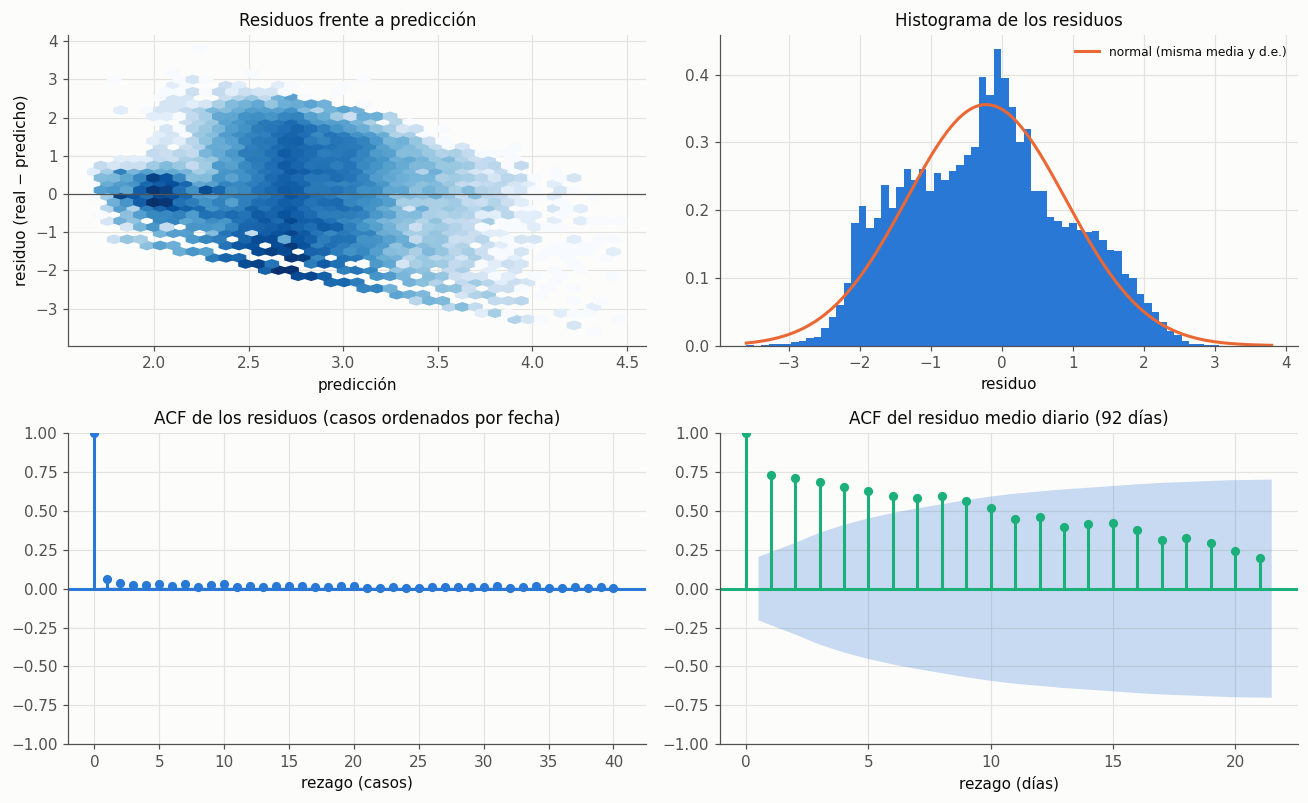

Ljung-Box (casos ordenados por fecha):
     lb_stat  lb_pvalue
1   176.5050        0.0
7   403.1111        0.0
20  570.3463        0.0
Ljung-Box (residuo medio diario):
     lb_stat  lb_pvalue
1    50.9448        0.0
7   297.3851        0.0
14  475.8754        0.0
Jarque-Bera: estadístico 868.6, p = 2.5e-189 | D'Agostino: p = 0
Asimetría 0.115, curtosis en exceso -0.634


BDS (3.000 residuos equiespaciados), dimensiones 2-4: [0.8529 0.7766 0.7045]


In [5]:
p = preds[bm]; res = yt - p
res_t = res[order]
daily = pd.Series(res, index=test.date.to_numpy()).groupby(level=0).mean()
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
axes[0, 0].hexbin(p, res, gridsize=40, cmap='Blues', mincnt=1, bins='log'); axes[0, 0].axhline(0, color=P.INK2, lw=0.8)
axes[0, 0].set_xlabel('predicción'); axes[0, 0].set_ylabel('residuo (real − predicho)'); axes[0, 0].set_title('Residuos frente a predicción')
axes[0, 1].hist(res, bins=70, color=P.SERIES[0], density=True)
xs = np.linspace(res.min(), res.max(), 200)
axes[0, 1].plot(xs, stats.norm.pdf(xs, res.mean(), res.std()), color=P.SERIES[1], lw=2, label='normal (misma media y d.e.)')
axes[0, 1].set_title('Histograma de los residuos'); axes[0, 1].legend(fontsize=8); axes[0, 1].set_xlabel('residuo')
plot_acf(res_t, lags=40, ax=axes[1, 0], color=P.SERIES[0], vlines_kwargs={'colors': P.SERIES[0]})
axes[1, 0].set_title('ACF de los residuos (casos ordenados por fecha)'); axes[1, 0].set_xlabel('rezago (casos)')
plot_acf(daily.to_numpy(), lags=21, ax=axes[1, 1], color=P.SERIES[2], vlines_kwargs={'colors': P.SERIES[2]})
axes[1, 1].set_title('ACF del residuo medio diario (92 días)'); axes[1, 1].set_xlabel('rezago (días)')
fig.tight_layout(); P.save(fig, 'e3_reg_residuos'); plt.show()
lb_case = acorr_ljungbox(res_t, lags=[1, 7, 20], return_df=True)
lb_day = acorr_ljungbox(daily.to_numpy(), lags=[1, 7, 14], return_df=True)
jb = stats.jarque_bera(res); dag = stats.normaltest(res)
print('Ljung-Box (casos ordenados por fecha):'); print(lb_case.round(4).to_string())
print('Ljung-Box (residuo medio diario):'); print(lb_day.round(4).to_string())
print(f'Jarque-Bera: estadístico {jb.statistic:.1f}, p = {jb.pvalue:.2g} | D\'Agostino: p = {dag.pvalue:.2g}')
print(f'Asimetría {stats.skew(res):.3f}, curtosis en exceso {stats.kurtosis(res):.3f}')
print(f'BDS (3.000 residuos equiespaciados), dimensiones 2-4:', np.round(bds(res[idx_bds], max_dim=4)[1], 4))

**Interpretación.** - **Residuos frente a predicción:** bandas diagonales, porque el objetivo es discreto (días enteros) y la
  predicción se mueve en un rango corto. La forma de abanico confirma la heterocedasticidad que detectó
  White. El modelo nunca predice ausencias muy cortas ni muy largas: subestima las largas y sobrestima las
  cortas (regresión hacia la media).
- **Histograma:** asimetría casi nula (0,12) pero colas más cortas que la normal (curtosis en exceso
  −0,63) y una forma irregular que hereda los picos del objetivo (1, 2, 3 días y el tope de 180).
  Jarque-Bera y D'Agostino rechazan la normalidad; con 45.861 casos rechazarían casi cualquier desviación,
  pero aquí la desviación también se ve en la gráfica. Para estos modelos (no paramétricos o penalizados)
  la normalidad no es un requisito de estimación; solo afectaría a intervalos de predicción basados en ella.
- **ACF y Ljung-Box:** caso a caso la autocorrelación es pequeña (0,06 en el rezago 1) pero significativa
  con tantos datos (Ljung-Box p ≈ 0): casos del mismo día y establecimiento se parecen. El residuo medio
  diario tiene una autocorrelación alta que decae lentamente (0,73 en el rezago 1): no es ruido, es la
  tendencia descendente de la prueba (censura) que el modelo no captura. Es un problema de
  especificación más que de dependencia entre casos.

**Conclusión del capítulo.** La regresión tiene poder predictivo bajo y su evaluación en la prueba está
afectada por la censura de la etiqueta. Una versión correcta debería modelar la censura (por ejemplo, un
modelo de supervivencia con el tiempo hasta el cierre del reporte como límite) o evaluar solo casos con
seguimiento suficiente. Se deja como siguiente paso; los resultados de este capítulo se leen como
comparación relativa entre modelos, no como desempeño absoluto.